In [ ]:
%pip install numpy 
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install plotly

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [65]:
df = pd.read_csv("data.csv")

mete_col = ['Diurnal temperature range (°C)', 'Mean temperature (°C)', 'Mean humidity (%)', 'Solar radiation (MJ/m²)', 'Air pressure (hPa)', 'Dew point temperature (°C)', 'Wind speed (km/h)', 'Mean UV']
flu_col = ["H1", "H3", "B", "AandB"]

In [66]:
# rows without SARS and COVID19 period

tdf = df[~(((df["From"] > "2003-02-21") & (df["From"] < "2003-06-23")) | ((df["From"] > "2020-01-23") & (df["From"] < "2023-03-01")) | (df["From"] < "2004-01-01"))]
tdf


,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB
70,2004,1,2004-01-04,5.50,18.00,78.63,11.50,1021.36,14.11,13.78,2.00,0.0,4.0,5.0,14.0
71,2004,2,2004-01-11,6.65,15.33,73.25,10.86,1020.24,10.55,14.03,2.14,0.0,9.0,0.0,13.0
72,2004,3,2004-01-18,5.24,10.10,69.66,7.33,1021.69,4.31,17.43,1.53,0.0,6.0,4.0,15.0
73,2004,4,2004-01-25,4.78,13.13,69.30,8.64,1019.00,7.36,13.25,1.71,0.0,16.0,3.0,20.0
74,2004,5,2004-02-01,4.72,11.73,85.70,3.56,1019.29,9.52,12.81,0.94,0.0,39.0,3.0,51.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1243,2026,26,2026-06-28,5.87,27.98,88.04,17.43,1008.09,25.65,13.56,3.56,214.0,476.0,111.0,812.0
1244,2026,27,2026-07-05,6.09,28.02,87.32,17.35,1005.17,25.44,11.67,3.86,304.0,483.0,123.0,928.0
1245,2026,28,2026-07-12,4.31,27.47,90.27,12.12,1004.22,25.60,10.67,2.56,383.0,533.0,124.0,1069.0
1246,2026,29,2026-07-19,6.32,28.44,84.48,18.33,1006.11,25.27,9.44,3.81,483.0,567.0,138.0,1217.0


---

In [67]:
df

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB
0,2002,36,2002-09-01,7.21,27.61,74.13,18.39,1007.66,22.09,9.44,4.00,1.0,12.0,3.0,19.0
1,2002,37,2002-09-08,5.53,26.24,83.09,10.65,1006.15,22.75,15.60,2.71,0.0,6.0,4.0,15.0
2,2002,38,2002-09-15,4.05,25.58,87.11,13.32,1009.57,22.98,17.52,3.27,0.0,4.0,4.0,13.0
3,2002,39,2002-09-22,3.86,25.18,86.02,10.42,1012.96,22.44,15.61,3.00,0.0,2.0,6.0,10.0
4,2002,40,2002-09-29,4.34,25.27,83.02,11.78,1013.02,21.92,12.91,2.86,0.0,6.0,2.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1243,2026,26,2026-06-28,5.87,27.98,88.04,17.43,1008.09,25.65,13.56,3.56,214.0,476.0,111.0,812.0
1244,2026,27,2026-07-05,6.09,28.02,87.32,17.35,1005.17,25.44,11.67,3.86,304.0,483.0,123.0,928.0
1245,2026,28,2026-07-12,4.31,27.47,90.27,12.12,1004.22,25.60,10.67,2.56,383.0,533.0,124.0,1069.0
1246,2026,29,2026-07-19,6.32,28.44,84.48,18.33,1006.11,25.27,9.44,3.81,483.0,567.0,138.0,1217.0


In [68]:
df[mete_col].describe()

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
count,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000
mean,5.727019,22.808333,79.317724,13.917973,1012.791947,18.731474,12.821995,2.847941
std,1.206021,4.933942,8.635992,4.649956,6.101638,6.037723,2.574058,1.110519
min,2.800000,9.020000,45.900000,2.480000,996.470000,0.730000,6.350000,0.610000
25%,4.900000,18.737500,74.740000,10.715000,1007.740000,14.310000,11.090000,2.000000
50%,5.660000,23.665000,81.195000,13.860000,1012.870000,20.000000,12.690000,2.710000
75%,6.520000,27.330000,85.357500,17.122500,1017.810000,24.382500,14.360000,3.570000
max,9.970000,30.160000,94.550000,26.570000,1026.740000,26.470000,28.230000,7.000000


In [69]:
df[flu_col].describe()

,H1,H3,B,AandB
count,1248.000000,1248.000000,1247.000000,1248.000000
mean,66.636218,115.048077,44.473937,257.649840
std,183.260440,233.869344,131.860434,436.354413
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,5.000000,3.000000,27.000000
50%,3.500000,27.000000,12.000000,102.000000
75%,46.000000,123.000000,40.500000,297.000000
max,1999.000000,2560.000000,1978.000000,4679.000000


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1248 entries, 0 to 1247
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1248 non-null   int64  
 1   Week                            1248 non-null   int64  
 2   From                            1248 non-null   object 
 3   Diurnal temperature range (°C)  1248 non-null   float64
 4   Mean temperature (°C)           1248 non-null   float64
 5   Mean humidity (%)               1248 non-null   float64
 6   Solar radiation (MJ/m²)         1248 non-null   float64
 7   Air pressure (hPa)              1248 non-null   float64
 8   Dew point temperature (°C)      1248 non-null   float64
 9   Wind speed (km/h)               1248 non-null   float64
 10  Mean UV                         1248 non-null   float64
 11  H1                              1248 non-null   float64
 12  H3                              12

In [71]:
print(f"Number of NA values in each rows: \n{df.isna().sum()}")

Number of NA values in each rows: 
Year                              0
Week                              0
From                              0
Diurnal temperature range (°C)    0
Mean temperature (°C)             0
Mean humidity (%)                 0
Solar radiation (MJ/m²)           0
Air pressure (hPa)                0
Dew point temperature (°C)        0
Wind speed (km/h)                 0
Mean UV                           0
H1                                0
H3                                0
B                                 1
AandB                             0
dtype: int64


In [72]:
print(f"Number of duplicated rows: {df.duplicated().sum()}")

Number of duplicated rows: 0


,H1,H3,B,AandB
Diurnal temperature range (°C),-0.026195,-0.054724,-0.003765,-0.030895
Mean temperature (°C),-0.112085,0.104497,-0.184519,-0.011241
Mean humidity (%),0.031306,0.090969,0.012147,0.064129
Solar radiation (MJ/m²),-0.101363,0.067361,-0.123339,-0.009338
Air pressure (hPa),0.099808,-0.101476,0.112838,-0.011038
Dew point temperature (°C),-0.081624,0.111766,-0.144302,0.010721
Wind speed (km/h),-0.007588,-0.020942,-0.023846,-0.018974
Mean UV,-0.131556,0.074104,-0.122813,-0.009936


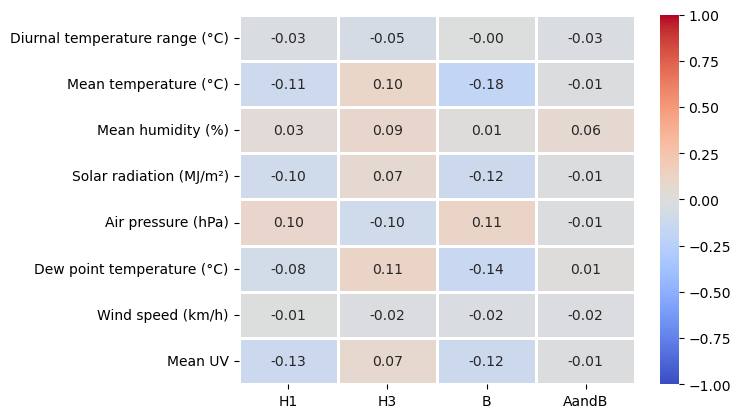

In [73]:
# correlation between meteorlogical factors and influenza detections
corr_df = df.drop(["Year", "Week", "From"], axis=1).corr()
corr_df = corr_df.loc[mete_col, flu_col]
display(corr_df)

sns.heatmap(corr_df, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

,H1,H3,B,AandB
Diurnal temperature range (°C),-0.022594,-0.048020,0.006265,-0.018993
Mean temperature (°C),-0.116195,0.124157,-0.199974,-0.003353
Mean humidity (%),0.040366,0.099141,0.011521,0.072147
Solar radiation (MJ/m²),-0.100756,0.095506,-0.123355,0.012545
Air pressure (hPa),0.113202,-0.106827,0.128194,-0.005435
Dew point temperature (°C),-0.082751,0.129207,-0.157583,0.018532
Wind speed (km/h),-0.011167,-0.024174,-0.027438,-0.023108
Mean UV,-0.135627,0.098402,-0.126268,0.007232


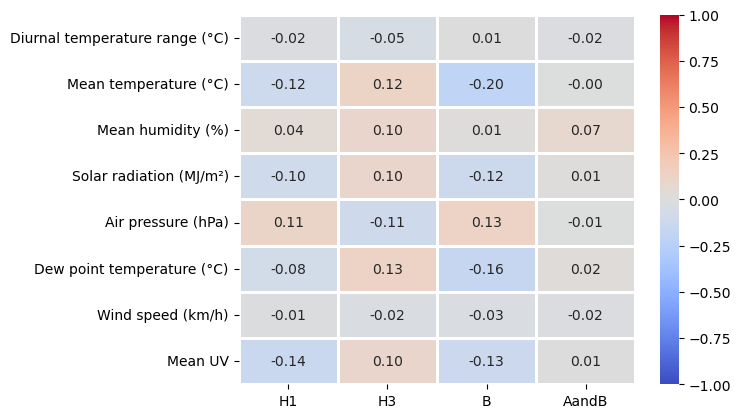

In [74]:
# correlation between meteorlogical factors and influenza detections
corr_df = tdf.drop(["Year", "Week", "From"], axis=1).corr()
corr_df = corr_df.loc[mete_col, flu_col]
display(corr_df)

sns.heatmap(corr_df, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

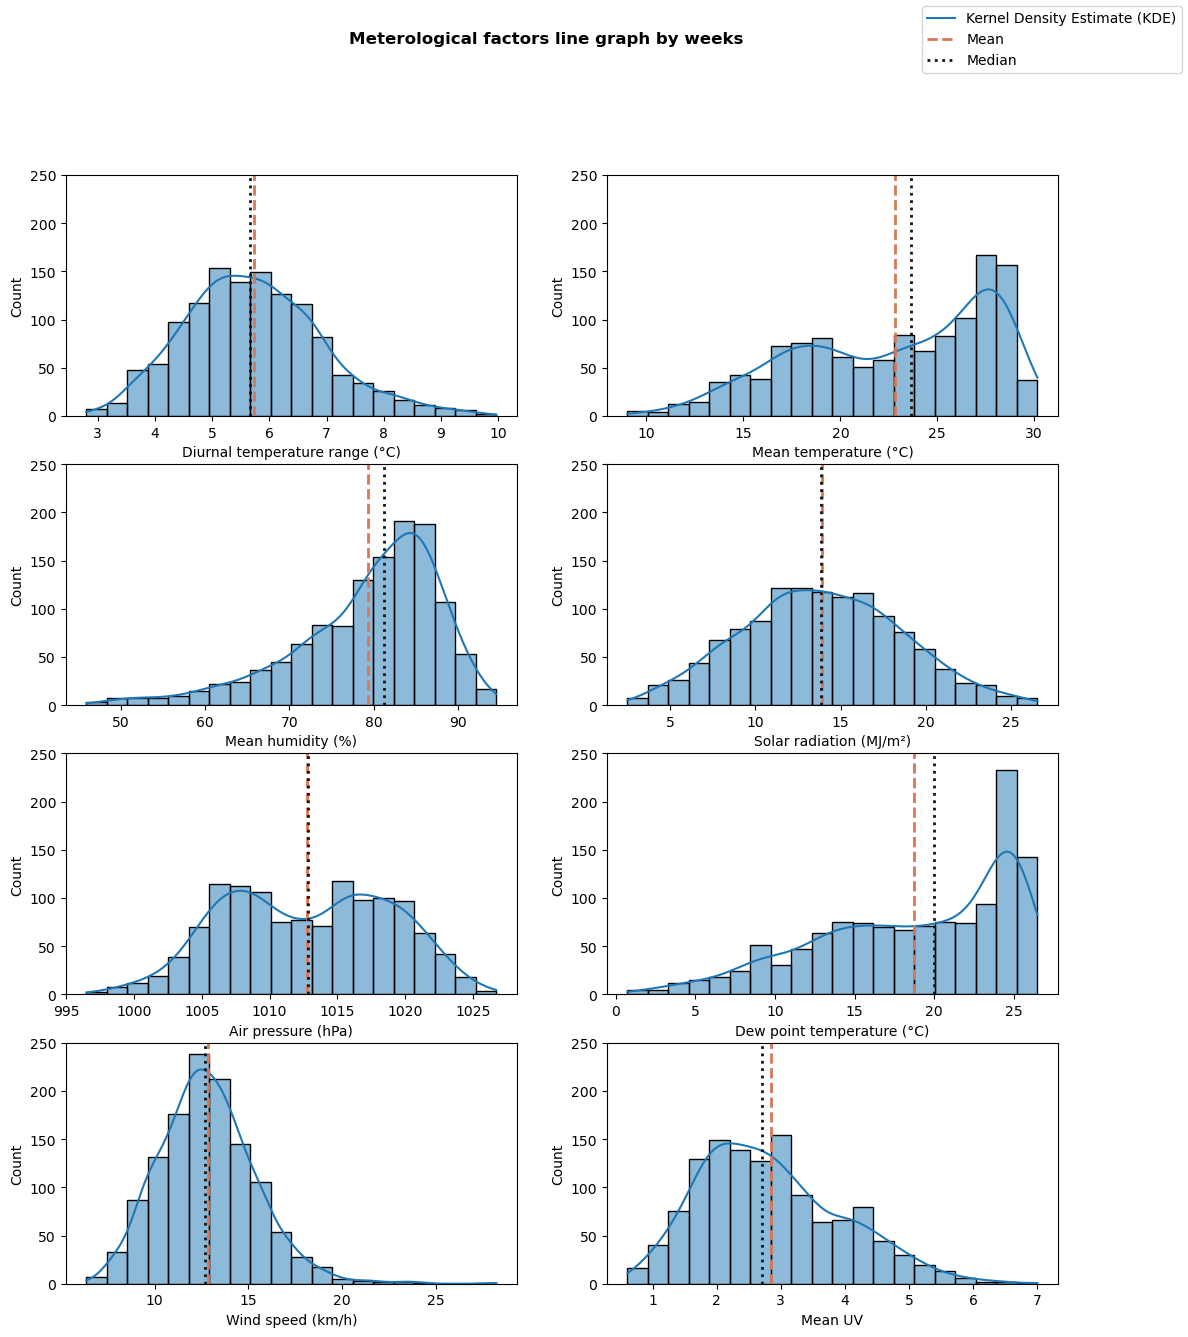

In [90]:
fig, axes = plt.subplots(4, 2, figsize=(6.4*2, 4.8*3))

for i, col in enumerate(mete_col):
    #sns.histplot(data=df, x=col, bins=20, ax=axes[i//2, i%2], kde=True, hue="Year")
    sns.histplot(data=df, x=col, bins=20, ax=axes[i//2, i%2], kde=True)
    axes[i//2, i%2].axvline(df[col].mean(), color="#d97757", linestyle="--", linewidth=2, label="Mean")
    axes[i//2, i%2].axvline(df[col].median(), color="#141413", linestyle=":", linewidth=2, label="Median")
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel("Count")
    axes[i//2, i%2].set_ylim(0, 250)
    
plt.suptitle("Meterological factors line graph by weeks", fontweight="bold")
fig.legend(["Kernel Density Estimate (KDE)", "Mean", "Median"])
plt.show()
    

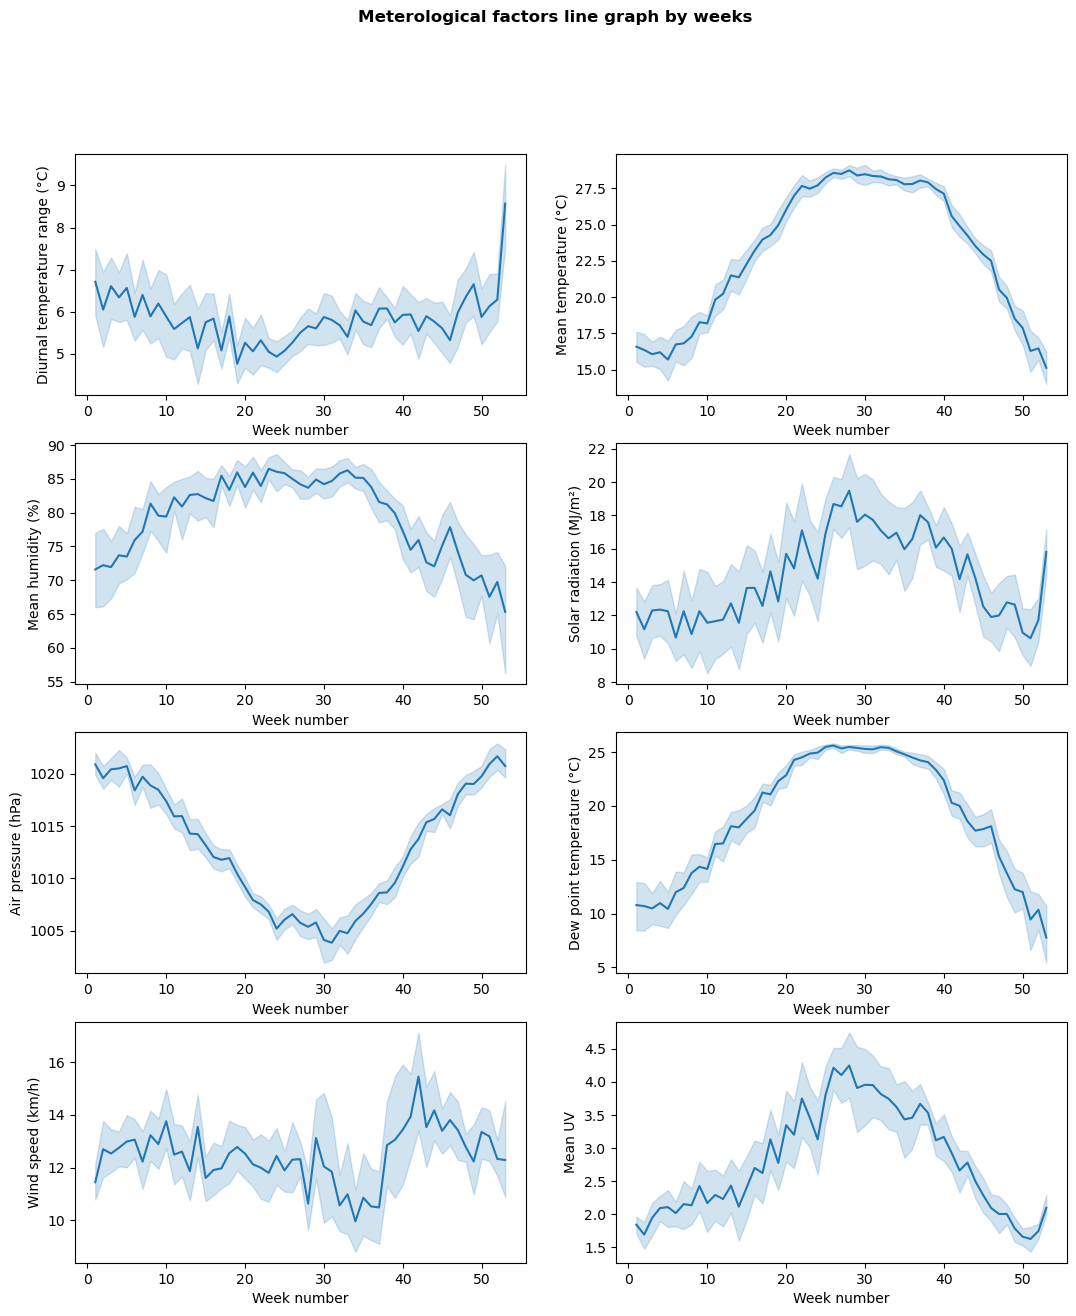

In [14]:
fig, axes = plt.subplots(4, 2, figsize=(6.4*2, 4.8*3))

for i, col in enumerate(mete_col):
    sns.lineplot(x="Week", y=col, data=df, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xlabel("Week number")
    axes[i//2, i%2].set_ylabel(col)
    
plt.suptitle("Meterological factors line graph by weeks", fontweight="bold")
plt.show()
    

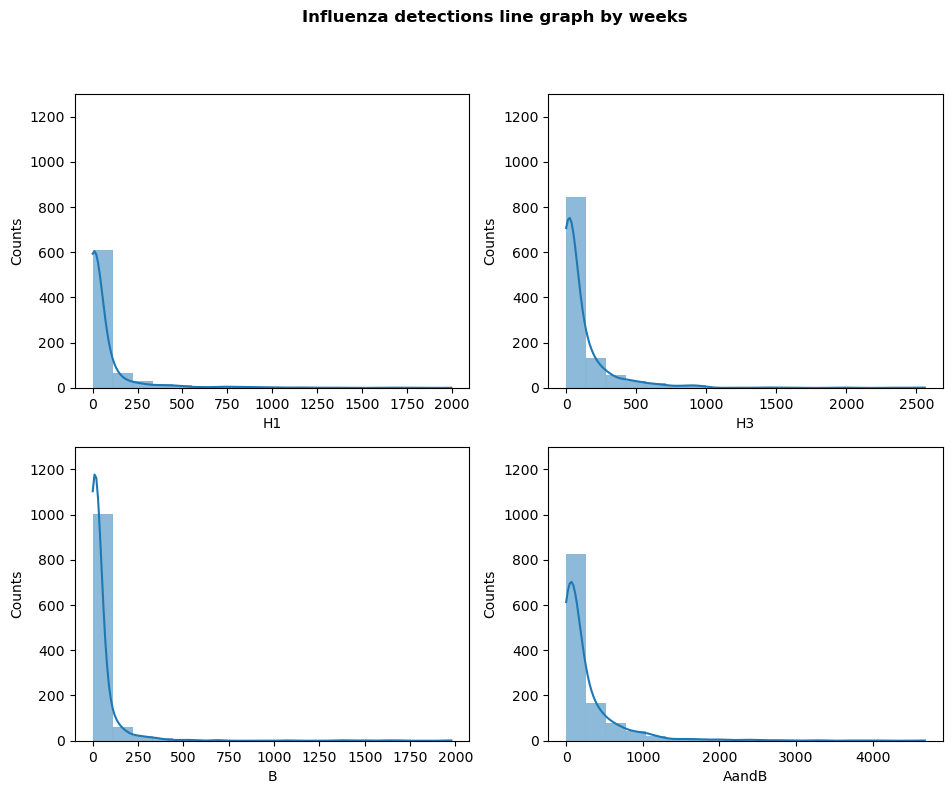

In [87]:
fig, axes = plt.subplots(2, 2, figsize=(6.4*1.75, 4.8*1.75))

for i, col in enumerate(flu_col):
    remaining = np.linspace(1, df[col].max(), 19)
    custom_bins = np.insert(remaining, 0, 0)
    
    sns.histplot(x=col, data=df, ax=axes[i//2, i%2], kde=True, bins=custom_bins)
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel("Counts")
    axes[i//2, i%2].set_ylim(0, 1300)
    
plt.suptitle("Influenza detections line graph by weeks", fontweight="bold")
plt.show()

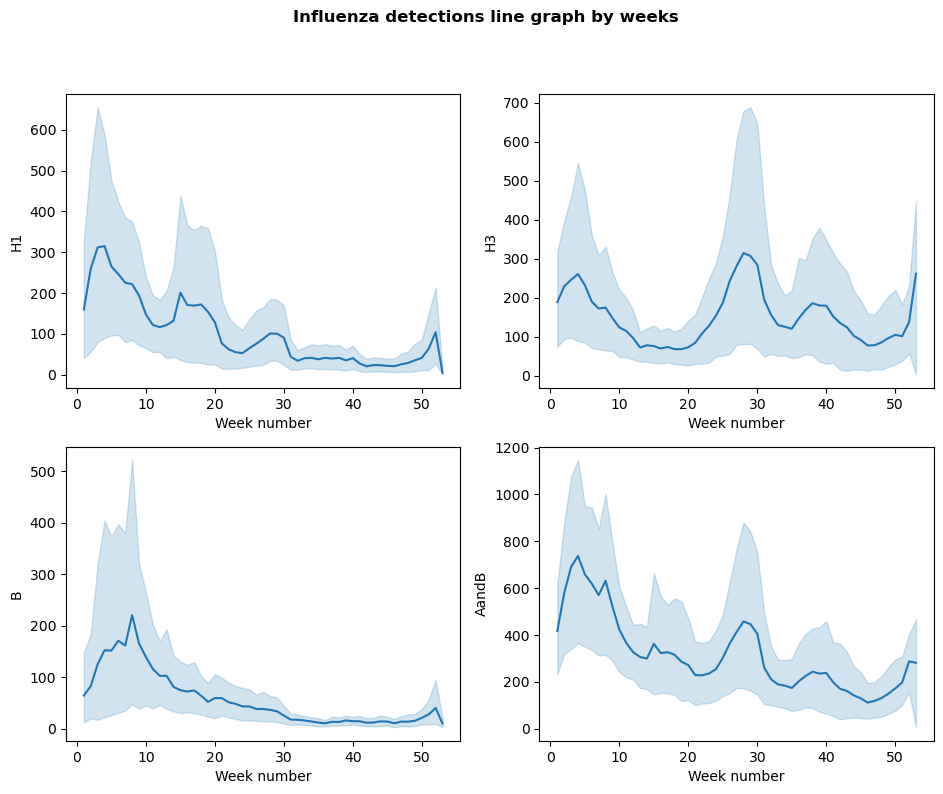

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(6.4*1.75, 4.8*1.75))

for i, col in enumerate(flu_col):
    sns.lineplot(x="Week", y=col, data=df, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xlabel("Week number")
    axes[i//2, i%2].set_ylabel(col)
    
plt.suptitle("Influenza detections line graph by weeks", fontweight="bold")
plt.show()

---

In [75]:
tdf = df[~(((df["From"] > "2003-02-21") & (df["From"] < "2003-06-23")) | ((df["From"] > "2020-01-23") & (df["From"] < "2023-03-01")) | (df["From"] < "2004-01-01"))]


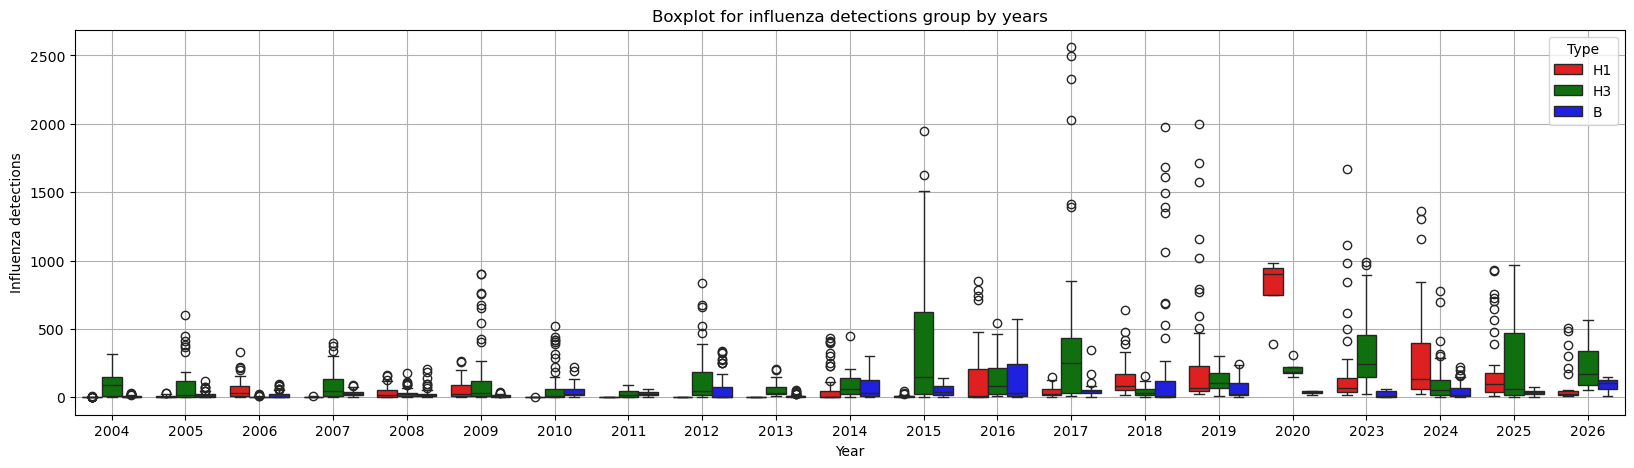

In [76]:
df_long = tdf.melt(
    id_vars=["Year"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

plt.figure(figsize=(20, 5))
sns.boxplot(df_long, x="Year", y="Influenza detections", hue="Type", palette=["red", "green", "blue"])

plt.title("Boxplot for influenza detections group by years")
plt.xlabel("Year")
plt.ylabel("Influenza detections")
plt.grid()
plt.show()

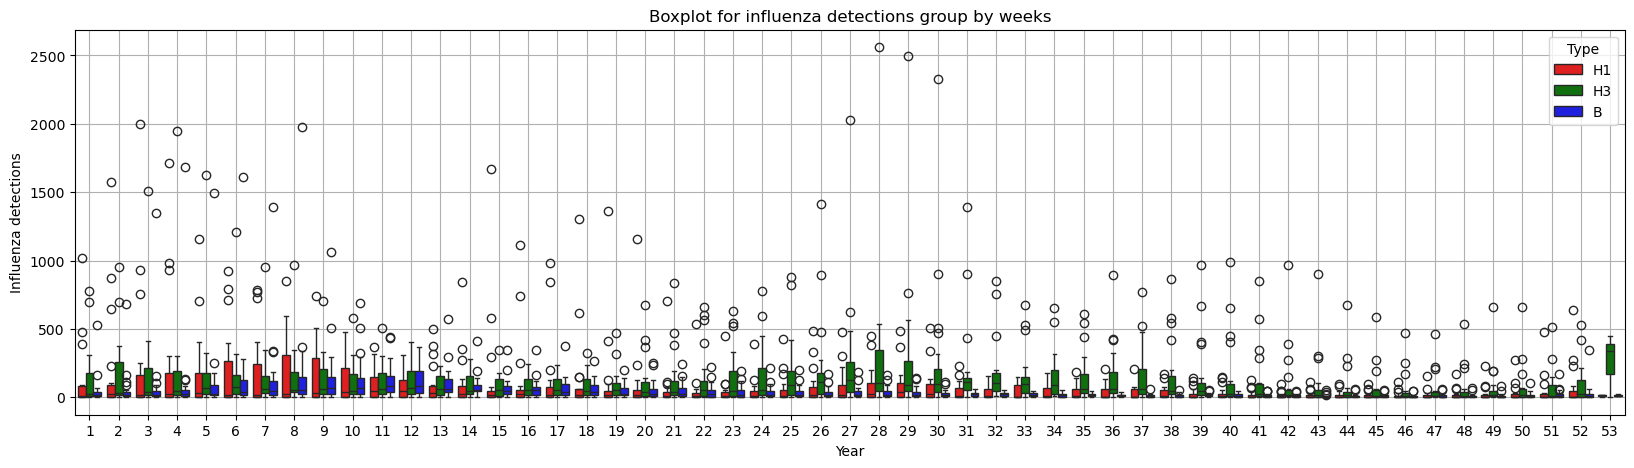

In [77]:
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

plt.figure(figsize=(20, 5))
sns.boxplot(df_long, x="Week", y="Influenza detections", hue="Type", palette=["red", "green", "blue"])

plt.title("Boxplot for influenza detections group by weeks")
plt.xlabel("Week")
plt.ylabel("Influenza detections")
plt.grid()
plt.show()

In [78]:
df_long = tdf.melt(
    id_vars=["From"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "From", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )
for year in sorted(tdf["Year"].unique()):
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    fig.add_vrect(start, end, line_width=0, fillcolor="red", opacity=0.3)
    
    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)

    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(255, 0, 0, 0.3)"),
        name="Winter", 
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(0, 0, 255, 0.3)"),
        name="Summer", 
        showlegend=True,
    )
)

fig.show()

In [79]:
tdf = df.drop(["Year", "From"], axis=1).groupby("Week").mean()
tdf["Week"] = tdf.index
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B", "AandB"],
    var_name="Type",  
    value_name="Number of influenza detections", 
)

fig = px.line(df_long, "Week", "Number of influenza detections", color="Type", 
              title="Number of detections in each week across every year", 
              width=1000, height=500
             )
fig.show()

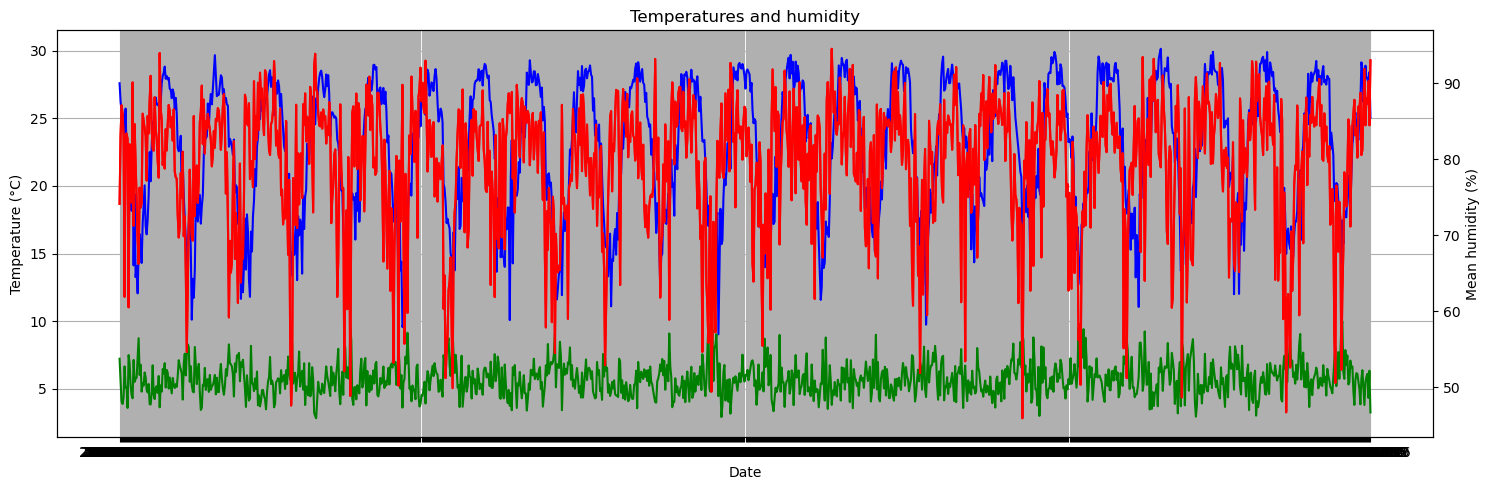

In [80]:
# to-do
fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(df["From"], df["Mean temperature (°C)"], color="blue")
ax1.plot(df["From"], df["Diurnal temperature range (°C)"], color="green")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")

ax2 = ax1.twinx()
line2 = ax2.plot(df["From"], df["Mean humidity (%)"], color="red")
ax2.plot(df["From"], df["Mean humidity (%)"], color="red")
ax2.set_ylabel("Mean humidity (%)")

ax1.grid()
'''
legend_elements = [
    Line2D(), 
    Line2D()
]
ax1.legend(handle=legend_elements)
'''

plt.title("Temperatures and humidity")
plt.tight_layout()
plt.show()

In [81]:
# to-do
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "Week", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )
for year in sorted(tdf["Year"].unique()):
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    fig.add_vrect(start, end, line_width=0, fillcolor="red", opacity=0.3)
    
    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)

    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(255, 0, 0, 0.3)"),
        name="Winter", 
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(0, 0, 255, 0.3)"),
        name="Summer", 
        showlegend=True,
    )
)

fig.show()

KeyError: 'Year'

In [ ]:
# graph of influenza based on timeline
fig, ax = plt.subplots(figsize=(85, 15))

ax.plot(tdf["From"], tdf["H1"], color="red")
ax.plot(tdf["From"], tdf["H3"], color="green")
ax.plot(tdf["From"], tdf["B"], color="blue")
ax.grid()

ax.set_title("Number of detections")
ax.set_xlabel("Year")
ax.set_ylabel("Number of detections")
ax.legend(["AH1", "AH3", "B"])


for year in sorted(tdf["Year"].unique()): 
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    ax.axvspan(start, end, color="#ffd1dc")

    mid_pt = start + (end - start) / 2
    ax.text(mid_pt, 2000, "Summer", horizontalalignment="center", verticalalignment="center", rotation=90, va="bottom", color="dimgray")

    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    ax.axvspan(start, end, color="#ADD8E6")

    mid_pt = start + (end - start) / 2
    ax.text(mid_pt, 2000, "Winter", horizontalalignment="center", verticalalignment="center", rotation=90, va="bottom", color="dimgray")

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)
    ax.axvspan(start, end, color="#ADD8E6")

plt.show()

---

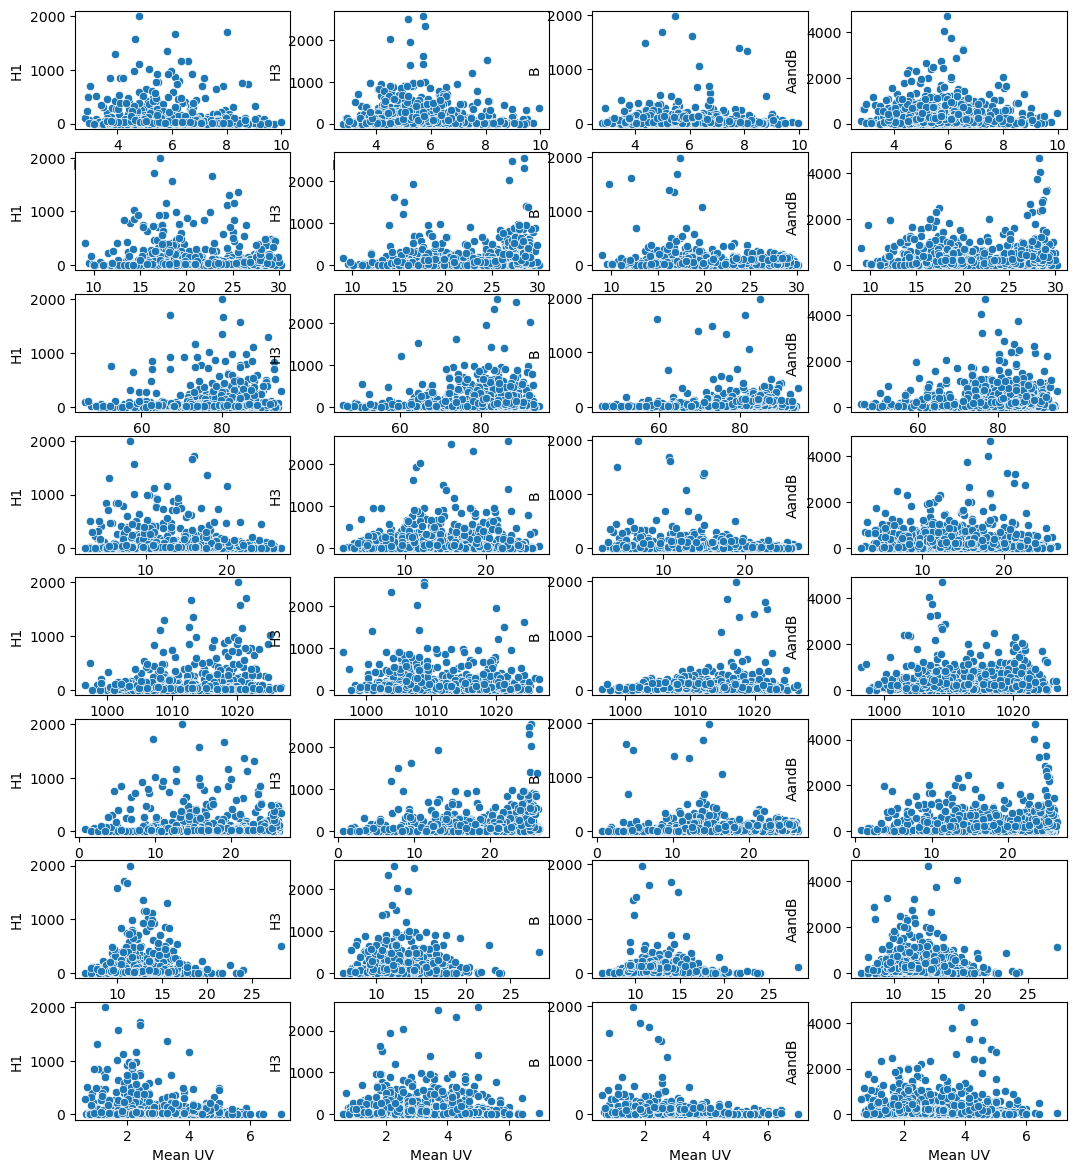

In [82]:
fig, axes = plt.subplots(8, 4, figsize=(6.4*2, 4.8*3))

for i, mete in enumerate(mete_col):
    for j, flu in enumerate(flu_col):
        sns.scatterplot(x=mete, y=flu, data=df, ax=axes[i, j])
        axes[i, j].set_xlabel(mete)
        axes[i, j].set_ylabel(flu)
        
plt.show()   